# Hierarchical Clustering: Agglomerative clustering, dendrogram generation, similarity measures and cluster evaluation

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering
from scipy.cluster.hierarchy import dendrogram, linkage

In [3]:
# Load dataset
df = pd.read_csv('Wholesale customers data.csv')

In [4]:
# Select numerical features
X = df[['Fresh', 'Milk', 'Grocery', 'Frozen', 'Detergents_Paper', 'Delicassen']]

In [5]:
# Standardization
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

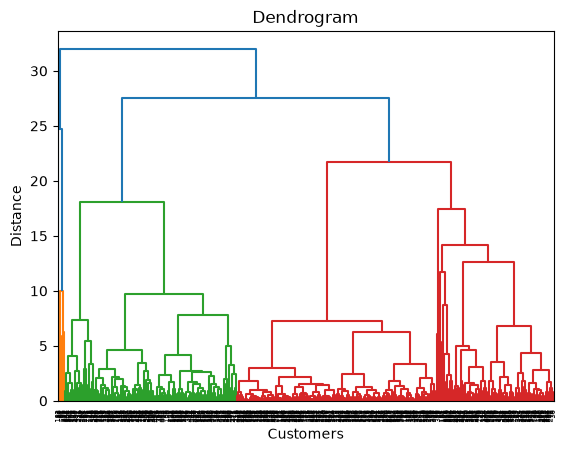

In [6]:
# Generate dendrogram
linked = linkage(X_scaled, method='ward')
dendrogram(linked)
plt.title('Dendrogram')
plt.xlabel('Customers')
plt.ylabel('Distance')
plt.show()

In [7]:
# Agglomerative clustering
model = AgglomerativeClustering(
    n_clusters=3,
    linkage='ward'
)

In [8]:
# Train model
labels = model.fit_predict(X_scaled)

In [9]:
# Add cluster column
df['Cluster'] = labels
print(df.head())

   Channel  Region  Fresh  Milk  Grocery  Frozen  Detergents_Paper  \
0        2       3  12669  9656     7561     214              2674   
1        2       3   7057  9810     9568    1762              3293   
2        2       3   6353  8808     7684    2405              3516   
3        1       3  13265  1196     4221    6404               507   
4        2       3  22615  5410     7198    3915              1777   

   Delicassen  Cluster  
0        1338        2  
1        1776        2  
2        7844        2  
3        1788        1  
4        5185        1  


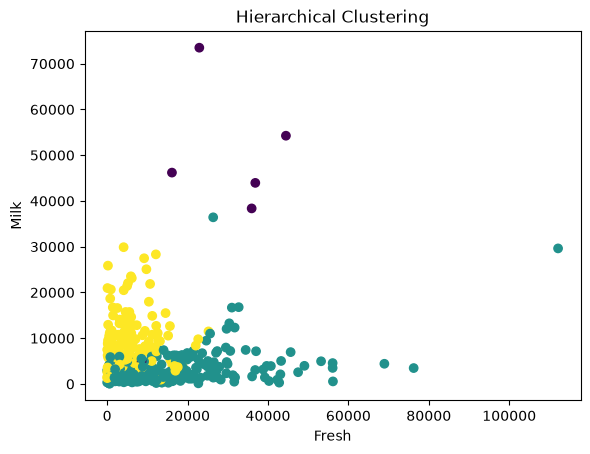

In [10]:
# Cluster visualization
plt.scatter(
    df['Fresh'],
    df['Milk'],
    c=labels
)
plt.xlabel('Fresh')
plt.ylabel('Milk')
plt.title('Hierarchical Clustering')
plt.show()